# Perfil do Turista no RN — análise estatística (Sírio / QR Code)
Fonte: painel público **Sírio – QR Code Perfil do Turista** (Fecomércio RN/Senac/Emprotur), atualizado em 08/12/2025, **n = 2.258 respostas**.
Os dados vêm **agregados** (contagem por categoria), então as medidas são calculadas para **dados agrupados** (ponto médio de classe).

Conceitos: média, mediana, moda, desvio padrão, distribuições (assimetria/curtose, normal vs. assimétrica) e z-score.

In [1]:
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
plt.rcParams['figure.figsize'] = (8, 3.6)
D = json.load(open('sirio_perfil_turista.json', encoding='utf-8'))
N = D['meta']['total_respostas']; N

2258

## 1. Funções para dados agrupados

In [2]:
def resumo_agrupado(classes, freqs, pontos_medios, nome=''):
    """Média, mediana, moda, desvio padrão, assimetria e curtose de dados em classes."""
    f = np.array(freqs, float); x = np.array(pontos_medios, float)
    n = f.sum(); media = (f*x).sum()/n
    dp = np.sqrt((f*(x-media)**2).sum()/(n-1))
    acum = f.cumsum(); i_med = np.searchsorted(acum, n/2)
    assim = (f*((x-media)/dp)**3).sum()/n
    curt = (f*((x-media)/dp)**4).sum()/n - 3
    return pd.Series({'n': int(n), 'média': round(media,2), 'classe mediana': classes[i_med],
                      'ponto médio da mediana': x[i_med], 'moda (classe modal)': classes[int(f.argmax())],
                      'desvio padrão': round(dp,2), 'CV %': round(100*dp/media,1),
                      'assimetria': round(assim,3), 'curtose (excesso)': round(curt,3)}, name=nome)

def barra(d, titulo, horizontal=False):
    s = pd.Series(d); ax = (s.plot.barh if horizontal else s.plot.bar)(color='#1f3a93')
    ax.set_title(titulo); plt.tight_layout(); plt.show()

## 2. Faixa etária

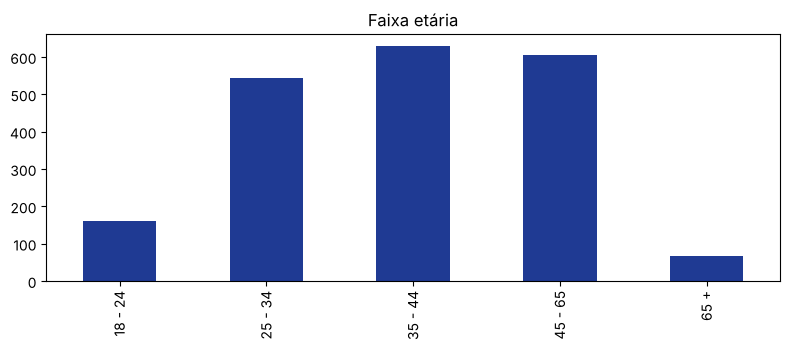

n                            2006
média                       41.01
classe mediana            35 - 44
ponto médio da mediana       39.5
moda (classe modal)       35 - 44
desvio padrão               12.49
CV %                         30.5
assimetria                    0.3
curtose (excesso)          -0.831
Name: Idade (anos), dtype: object

In [3]:
fe = D['faixa_etaria']; barra(fe, 'Faixa etária')
idade = resumo_agrupado(list(fe), list(fe.values()), [21, 29.5, 39.5, 55, 70], 'Idade (anos)'); idade

**Leitura:** classe modal 35–44, mediana na mesma classe, média ≈ 41 anos. Assimetria 0,3 (leve à direita) e curtose negativa → distribuição **quase simétrica e achatada (platicúrtica)**, sem caudas pesadas (poucos 18–24 e 65+). Desvio padrão ≈ 12,5 anos. Turista adulto em idade produtiva.

## 3. Gasto médio diário (R$)

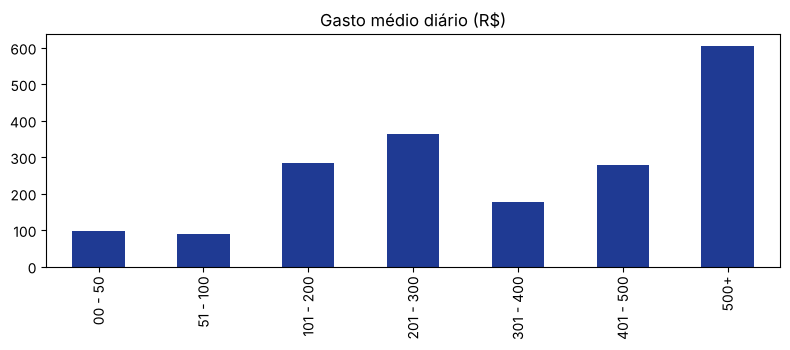

n                              1895
média                        382.24
classe mediana            301 - 400
ponto médio da mediana        350.5
moda (classe modal)            500+
desvio padrão                214.63
CV %                           56.1
assimetria                    0.019
curtose (excesso)            -1.404
Name: Gasto diário (R$), dtype: object

In [4]:
g = D['gasto_medio_diario_faixa']; barra(g, 'Gasto médio diário (R$)')
# 500+ é classe aberta: ponto médio assumido = 650 (premissa; teste a sensibilidade abaixo)
pm = [25, 75.5, 150.5, 250.5, 350.5, 450.5, 650]  # 650 = premissa conservadora
gasto = resumo_agrupado(list(g), list(g.values()), pm, 'Gasto diário (R$)'); gasto

In [5]:
# Sensibilidade da média à premissa da classe aberta vs. média real do painel (R$ 398,62)
for p in [550, 650, 700, 750]:
    r = resumo_agrupado(list(g), list(g.values()), pm[:-1]+[p])
    print(f'500+ -> {p}: média={r["média"]}, dp={r["desvio padrão"]}')
print('Média reportada pelo painel:', D['kpis']['gasto_medio_diario_brl'])

500+ -> 550: média=350.26, dp=176.37
500+ -> 650: média=382.24, dp=214.63
500+ -> 700: média=398.23, dp=234.9
500+ -> 750: média=414.22, dp=255.69
Média reportada pelo painel: 398.62


**Leitura:** **moda = 500+** (32% das respostas), **mediana na classe 301–400**, média ≈ R$ 380–400. Curtose muito negativa (−1,4) com assimetria ~0 não significa “normal”: é o sinal de uma distribuição **bimodal** (pico em 201–300 e outro em 500+). Sugere dois públicos — turista econômico/família e turista de alto gasto (resort, pacote, evento). A média real do painel (R$ 398,62) é reproduzida com ponto médio ≈ R$ 700 para a classe aberta. CV de 56% → gasto muito heterogêneo; a média isolada esconde os dois segmentos.

## 4. Dias de permanência — onde o z-score faz diferença

In [6]:
dp_ = {k:v for k,v in D['dias_permanencia'].items() if k != '+ DE 10'}
dias = np.repeat(np.array(list(map(int, dp_))), list(dp_.values()))
print('n =', len(dias), '| excluídas', D['dias_permanencia']['+ DE 10'], 'respostas "+ DE 10" (classe aberta)')
desc = pd.Series({'média': dias.mean(), 'mediana': np.median(dias), 'moda': stats.mode(dias, keepdims=False).mode,
                  'desvio padrão': dias.std(ddof=1), 'assimetria': stats.skew(dias), 'curtose': stats.kurtosis(dias)}).round(2); desc

n = 1943 | excluídas 56 respostas "+ DE 10" (classe aberta)


média              6.44
mediana            6.00
moda               7.00
desvio padrão     11.41
assimetria        19.78
curtose          541.48
dtype: float64

Valores com |z| > 3 (outliers):
56     1
60     7
90     5
121    1
180    1
365    1

Sem outliers: média=5.67, mediana=6.0, dp=3.42


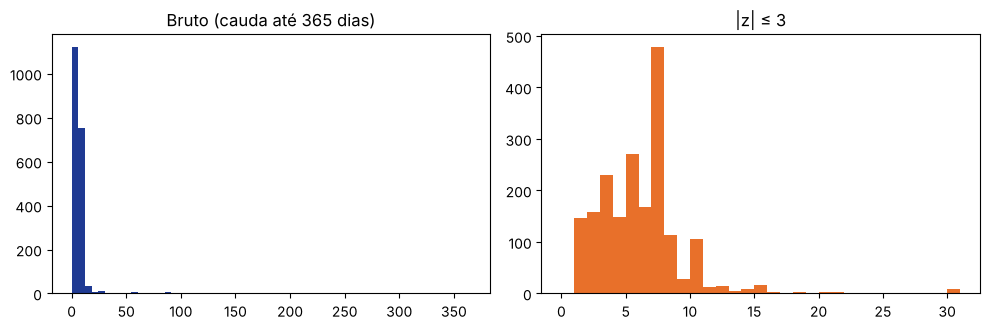

In [7]:
z = (dias - dias.mean())/dias.std(ddof=1)
out = pd.Series(dias[np.abs(z) > 3]).value_counts().sort_index()
print('Valores com |z| > 3 (outliers):'); print(out.to_string())
lim = dias[np.abs(z) <= 3]
print(f'\nSem outliers: média={lim.mean():.2f}, mediana={np.median(lim)}, dp={lim.std(ddof=1):.2f}')
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].hist(dias, bins=60, color='#1f3a93'); ax[0].set_title('Bruto (cauda até 365 dias)')
ax[1].hist(lim, bins=range(0, 32), color='#e8702a'); ax[1].set_title('|z| ≤ 3'); plt.tight_layout(); plt.show()

**Leitura:** **moda = 7 dias** (pacote de uma semana), mediana = 6, média bruta = 6,4 com **desvio padrão 11,4** — maior que a própria média. Causa: 16 respostas de 56 a 365 dias (estadia de trabalho/residência temporária), que o z-score marca como outliers (|z|>3). Assimetria 19,8 e curtose 541 = distribuição **extremamente assimétrica à direita (leptocúrtica)**. Sem outliers: média 5,7, mediana 6, dp 3,4 → o turista típico fica **~1 semana**; para essa variável, **mediana e moda descrevem melhor que a média**.

## 5. Renda individual (salários mínimos) — escalas harmonizadas

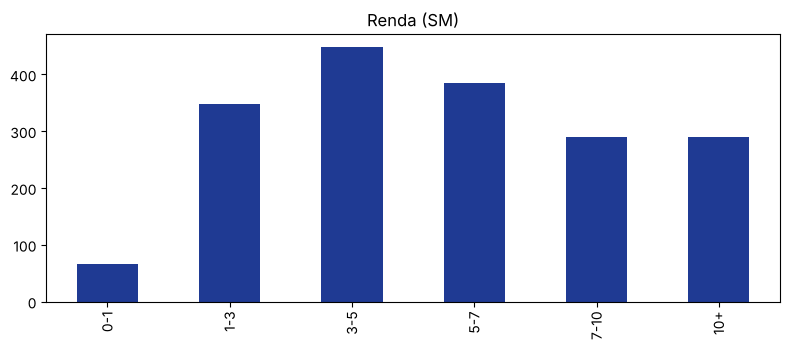

n                          1827
média                      6.06
classe mediana              5-7
ponto médio da mediana      6.0
moda (classe modal)         3-5
desvio padrão              3.73
CV %                       61.5
assimetria                0.664
curtose (excesso)        -0.592
Name: Renda (SM), dtype: object

In [8]:
r = D['renda_harmonizada']; barra(r, 'Renda (SM)')
renda = resumo_agrupado(list(r), list(r.values()), [0.5, 2, 4, 6, 8.5, 13], 'Renda (SM)'); renda

**Leitura:** classe modal 3–5 SM, mediana em 5–7 SM, assimetria positiva leve. Turista de **renda média-alta** — coerente com escolaridade (64% superior ou pós).

## 6. Origem do turista — concentração e z-score por estado

In [9]:
eo = pd.Series(D['estado_origem']).drop('ESTRANGEIRO')
zs = ((eo - eo.mean())/eo.std(ddof=1)).round(2)
t = pd.DataFrame({'respostas': eo, '% de N': (100*eo/N).round(1), 'z-score': zs})
t.sort_values('respostas', ascending=False).head(10)

,respostas,% de N,z-score
SP,455,20.2,3.18
RN,399,17.7,2.70
MG,193,8.5,0.94
PR,95,4.2,0.10
PE,95,4.2,0.10
PB,89,3.9,0.05
CE,79,3.5,-0.03
RJ,75,3.3,-0.07
RS,66,2.9,-0.14
GO,65,2.9,-0.15


Média por estado: 82.9 | mediana: 35.0 | dp: 117.0
Top 2 (SP+RN) = 44.8 % das respostas com UF


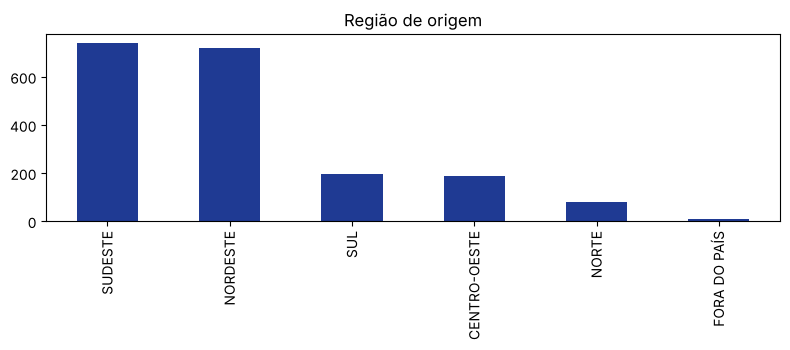

In [10]:
print('Média por estado:', round(eo.mean(),1), '| mediana:', eo.median(), '| dp:', round(eo.std(ddof=1),1))
print('Top 2 (SP+RN) =', round(100*(eo['SP']+eo['RN'])/eo.sum(),1), '% das respostas com UF')
barra(D['regiao_origem'], 'Região de origem')

**Leitura:** SP (z≈+3,2) e RN (z≈+2,7) são outliers de demanda (|z|>2) e somam 45% das respostas com UF; MG (z≈+0,9) vem bem atrás. A distribuição por estado é **fortemente assimétrica (lei de potência)**: média ≫ mediana. Sudeste ≈ Nordeste (33% cada). Ponto de atenção: **~18% são residentes do RN** — turismo interno relevante, mas isso também mistura “turista” com morador em deslocamento.

## 7. Concentração geográfica e temporal da coleta (viés amostral)

,2023-11,2023-12,2024-01,2024-02,2024-03,2024-04,2024-05,2024-06,2024-07,2024-08,2024-09,2024-10,2024-11,2024-12,2025-01,2025-02,2025-10
respostas,13.0,209.00,33.00,21.00,26.00,121.00,30.00,40.00,67.00,83.00,45.00,83.00,80.00,63.00,53.00,10.00,1281.00
z,-0.4,0.25,-0.33,-0.37,-0.36,-0.04,-0.34,-0.31,-0.22,-0.17,-0.29,-0.17,-0.18,-0.23,-0.27,-0.41,3.83


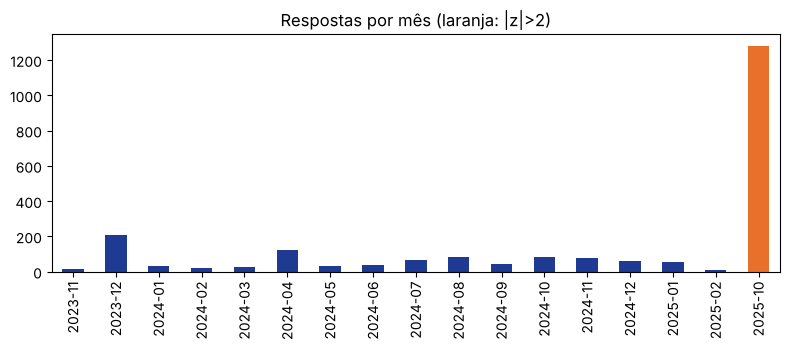

LESTE POTIGUAR      81.0
OESTE POTIGUAR      16.3
CENTRAL POTIGUAR     2.5
AGRESTE POTIGUAR     0.2


In [11]:
mes = pd.Series(D['respostas_por_mes'])
zm = ((mes - mes.mean())/mes.std(ddof=1)).round(2)
display(pd.DataFrame({'respostas': mes, 'z': zm}).T)
ax = mes.plot.bar(color=['#e8702a' if v>2 else '#1f3a93' for v in zm]); ax.set_title('Respostas por mês (laranja: |z|>2)'); plt.tight_layout(); plt.show()
meso = pd.Series(D['mesorregiao_aplicacao']); print((100*meso/meso.sum()).round(1).to_string())

**Leitura crítica:** **out/2025 concentra 57% da amostra** (z ≈ +3,8) e **81% das coletas foram no Leste Potiguar** (Natal sozinha 46%). Não há dados de mar–set/2025. Logo a amostra é **de conveniência, não probabilística**: os resultados descrevem *quem escaneou o QR code*, não o turista do RN em geral. Sazonalidade (alta temporada jul/dez–jan) não pode ser medida com segurança.

## 8. Satisfação — escala Likert convertida em nota (1–5) e NPS

In [12]:
esc = {'PÉSSIMO':1,'RUIM':2,'REGULAR':3,'BOM':4,'ÓTIMO':5}
lin = []
for item, d in D['avaliacao'].items():
    x = np.repeat([esc[k] for k in esc if k in d], [d[k] for k in esc if k in d])
    lin.append({'item': item, 'n válido': len(x), 'média': x.mean(), 'mediana': np.median(x), 'moda': stats.mode(x, keepdims=False).mode,
                'dp': x.std(ddof=1), '% não sabe': 100*d.get('NÃO SABE',0)/(len(x)+d.get('NÃO SABE',0))})
av = pd.DataFrame(lin).set_index('item').round(2)
av['z da média (entre itens)'] = ((av['média']-av['média'].mean())/av['média'].std(ddof=1)).round(2)
av.sort_values('média')

,n válido,média,mediana,moda,dp,% não sabe,z da média (entre itens)
item,,,,,,,
infraestrutura_passeios,1928,3.96,4.0,4,0.85,1.73,-1.51
trajeto_aeroporto,1474,4.19,4.0,4,0.82,24.72,-0.45
atendimento_pontos_turisticos,1949,4.36,4.0,4,0.60,0.46,0.33
transportes_turisticos,678,4.42,5.0,5,0.68,0.00,0.61
conhecimento_guias,1246,4.51,5.0,5,0.63,36.27,1.02


In [13]:
k = D['kpis']; n = k['nps_respostas_validas']
p, d_ = k['nps_promotores']/n, k['nps_detratores']/n
nps = 100*(p-d_)
# erro padrão do NPS (variável -1/0/+1)
se = 100*np.sqrt((p + d_ - (p-d_)**2)/n)
print(f'NPS = {nps:.2f}  | IC95% ≈ [{nps-1.96*se:.1f}; {nps+1.96*se:.1f}]  (n={n})')

NPS = 87.51  | IC95% ≈ [84.9; 90.1]  (n=1073)


**Leitura:** todos os itens têm mediana 4 (Bom) e moda 4–5. **Infraestrutura dos locais de passeio** tem a menor média e maior desvio padrão (z mais negativo) → é o ponto fraco. **Trajeto do aeroporto** vem em seguida e tem 25% de “não sabe”. NPS 87,5 com IC95% estreito (~±2,5) → recomendação muito alta, mas **viés de coleta**: o QR é oferecido por guia/receptivo durante a experiência, o que tende a inflar satisfação.

## 9. Conclusões (o que os dados permitem inferir)
| # | Achado | Conceito usado | Confiança |
|---|---|---|---|
| 1 | Perfil típico: adulto 35–44 anos, superior completo, renda 3–7 SM, viaja com cônjuge/família | moda, mediana | alta (descritivo) |
| 2 | Gasto diário é **bimodal** (201–300 e 500+): dois segmentos de público | moda, assimetria | média (classe aberta) |
| 3 | Permanência típica = 5–7 dias; média bruta distorcida por outliers | z-score, mediana | alta |
| 4 | Origem concentrada em SP e RN (z > 3); Sudeste ≈ Nordeste | z-score, assimetria | média |
| 5 | Infraestrutura de passeios é o elo fraco da experiência | média/dp Likert, z | média |
| 6 | Amostra **não probabilística** (57% em out/2025, 81% no Leste) → não generalizar para o RN | z-score temporal | alta |

**Limitação central:** dados agregados + coleta por conveniência. Para inferência populacional seriam necessários microdados e ponderação (por mês, região de aplicação e origem).